# EXP-E2-04 : le contexte aide-t-il nos modèles ?

**Question.** À méthode égale, donner le contexte (fériés, vacances, grèves, météo prévue à J−2) réduit-il l'erreur ? On compare chaque modèle **avec et sans contexte** : même méthode, même graine, même réglage.

**Lecture, figée le 2026-11-27 avant les scores** ([fiche](../reports/experiments/EXP-E2-04.md)) :
- Seuil de bruit : **0,357** vélo/h, l'étendue entre les 3 graines du MLP dans EXP-E2-03. Un écart plus petit se lit « pas d'effet mesurable ».
- L'application garde le HGB avec contexte, sauf si « sans contexte » fait mieux d'au moins ce seuil.
- Étape 2 (retirer un groupe de contexte à la fois, HGB) : seulement si l'écart du HGB dépasse le seuil.
- Diagnostics : jours fériés (14/07, 15/08), jours de pluie prévue (au moins 1 mm). Aucune grève dans la période.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.models.known import batch as B
from src.models.known import demo as D
from src.models.known import predict as P
from src.models.known import score as S

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)
SNAPSHOT = "hist-20261117"
PRED = P.data_path("predictions")

NAMES = {
    "e2-hgb-ctx-20260701-s0-b357": "HGB avec contexte",
    "e2-hgb-noctx-20260701-s0-0af3": "HGB sans contexte",
    "e2-mlp-ctx-20260701-s0-9ce9": "MLP avec contexte",
    "e2-mlp-noctx-20260701-s0-5114": "MLP sans contexte",
}
THRESHOLD = 0.357

## 1. Étape 1 : avec ou sans contexte, par paire

In [2]:
rows = []
for pair, (ctx, noctx) in {"HGB": ("e2-hgb-ctx-20260701-s0-b357", "e2-hgb-noctx-20260701-s0-0af3"),
                           "MLP": ("e2-mlp-ctx-20260701-s0-9ce9", "e2-mlp-noctx-20260701-s0-5114")}.items():
    js = json.loads((PRED / "EXP-E2-04" / f"scores_{pair.lower()}.json").read_text())["scores"]
    for lecture in ("système", "brut"):
        a, b = js[lecture][ctx], js[lecture][noctx]
        delta = b["mae_macro"] - a["mae_macro"]
        rows.append({"paire": pair, "lecture": lecture, "MAE avec": a["mae_macro"], "MAE sans": b["mae_macro"],
                     "écart (sans - avec)": delta, "biais avec": a["bias"], "biais sans": b["bias"],
                     "cas comparés": a["n_compared_cases"],
                     "lecture du seuil": "le contexte aide" if delta > THRESHOLD else ("sans contexte meilleur" if delta < -THRESHOLD else "pas d'effet mesurable")})
step1 = pd.DataFrame(rows)
step1

,paire,lecture,MAE avec,MAE sans,écart (sans - avec),biais avec,biais sans,cas comparés,lecture du seuil
0,HGB,système,22.254,22.896,0.641,-1.126,-0.371,5613,le contexte aide
1,HGB,brut,22.254,22.896,0.641,-1.126,-0.371,5613,le contexte aide
2,MLP,système,22.232,23.379,1.146,-0.815,2.623,5613,le contexte aide
3,MLP,brut,22.197,23.355,1.158,-0.952,2.501,5577,le contexte aide


## 2. Compteurs améliorés et diagnostics par type de jour

On charge les 4 prévisions, puis on refait le score sur des groupes de jours (`score.score_by_group`). Le calcul prend quelques minutes.

In [3]:
cases = S.load_cases()
fc = pd.concat([S.load_forecasts(PRED / "EXP-E2-04"), S.load_forecasts(PRED / "EXP-E2", list(NAMES)[::2])])
fc = fc[fc.method_run_id.isin(NAMES)]
obs = S.load_observations(cases)
table, per_counter = S.score_detail(cases, fc, obs)
by = per_counter.pivot_table(index="counter_id", columns="method_run_id", values="MAE")
for pair, (ctx, noctx) in {"HGB": ("e2-hgb-ctx-20260701-s0-b357", "e2-hgb-noctx-20260701-s0-0af3"),
                           "MLP": ("e2-mlp-ctx-20260701-s0-9ce9", "e2-mlp-noctx-20260701-s0-5114")}.items():
    better = (by[ctx] < by[noctx]).sum(); worse = (by[ctx] > by[noctx]).sum()
    print(f"{pair} : le contexte améliore {better} compteurs et en dégrade {worse} (sur {len(by)})")
table.rename(index=NAMES)[["mae_macro", "bias", "n_compared_cases"]]

HGB : le contexte améliore 86 compteurs et en dégrade 9 (sur 95)
MLP : le contexte améliore 88 compteurs et en dégrade 7 (sur 95)


,mae_macro,bias,n_compared_cases
method_run_id,,,
MLP avec contexte,22.232,-0.814,5613
HGB avec contexte,22.254,-1.126,5613
HGB sans contexte,22.896,-0.371,5613
MLP sans contexte,23.379,2.623,5613


In [4]:
context = P.load_context(SNAPSHOT)
day = pd.to_datetime(cases.origin, utc=True).dt.tz_convert("Europe/Paris").dt.strftime("%Y-%m-%d")
rain = D.rainy_days(context, threshold_mm=1.0)
holiday = pd.Series(np.where(day.isin(["2026-07-14", "2026-08-15"]), "férié", "autre jour"), index=cases.case_id)
rainy = pd.Series(np.where(day.isin(rain), "pluie prévue >= 1 mm", "sec"), index=cases.case_id)
print("jours de pluie prévue en juillet-août :", sorted(d for d in rain if "2026-07-01" <= d < "2026-09-01"))
diag = pd.concat([S.score_by_group(cases, fc, obs, holiday), S.score_by_group(cases, fc, obs, rainy)])
diag = diag["mae_macro"].unstack("method_run_id").rename(columns=NAMES)
diag["HGB : sans - avec"] = diag["HGB sans contexte"] - diag["HGB avec contexte"]
diag["MLP : sans - avec"] = diag["MLP sans contexte"] - diag["MLP avec contexte"]
diag.round(2)

jours de pluie prévue en juillet-août : ['2026-07-16', '2026-08-25', '2026-08-27', '2026-08-28', '2026-08-29']


method_run_id,HGB avec contexte,HGB sans contexte,MLP avec contexte,MLP sans contexte,HGB : sans - avec,MLP : sans - avec
group,,,,,,
autre jour,22.20,22.53,22.21,23.20,0.34,0.98
férié,24.31,33.88,22.91,28.87,9.57,5.96
pluie prévue >= 1 mm,23.79,23.15,26.19,23.03,-0.64,-3.16
sec,22.15,22.91,21.91,23.45,0.75,1.53


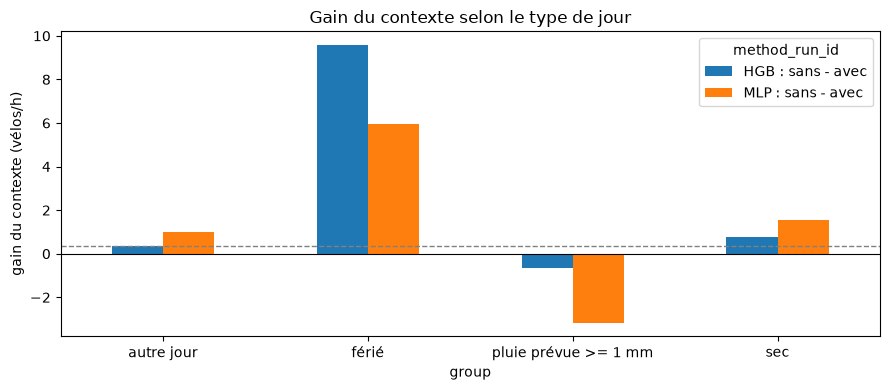

In [5]:
ax = diag[["HGB : sans - avec", "MLP : sans - avec"]].plot.bar(figsize=(9, 4), rot=0)
ax.axhline(THRESHOLD, color="0.5", ls="--", lw=1); ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("gain du contexte (vélos/h)"); ax.set_title("Gain du contexte selon le type de jour")
plt.tight_layout()

## 3. Étape 2 : quel groupe de contexte compte (HGB)

On réapprend le HGB sans un groupe à la fois, avec le même réglage (`max_iter=2000`). L'écart est lu contre le HGB avec tout le contexte.

In [6]:
step2 = []
for name in ["sans-calendar", "sans-strikes", "sans-weather"]:
    path = PRED / "EXP-E2-04" / f"scores_hgb_{name}.json"
    if not path.exists():
        print("pas encore calculé :", name); continue
    js = json.loads(path.read_text())["scores"]["système"]
    full = js["e2-hgb-ctx-20260701-s0-b357"]["mae_macro"]
    other = [v for k, v in js.items() if k != "e2-hgb-ctx-20260701-s0-b357"][0]
    step2.append({"modèle": name, "MAE": other["mae_macro"], "MAE avec tout": full,
                  "perte sans ce groupe": other["mae_macro"] - full})
pd.DataFrame(step2)

,modèle,MAE,MAE avec tout,perte sans ce groupe
0,sans-calendar,22.735,22.254,0.480
1,sans-strikes,22.148,22.254,-0.106
2,sans-weather,22.423,22.254,0.168
